# Kasus A: Deteksi Penipuan Pembukaan Rekening Bank (BAF Base)
**Tujuan:** memberi skor tiap pengajuan; tangkap penipu sebanyak mungkin dengan syarat nasabah jujur yang tertandai ≤ 5%.
**Metrik:** TPR pada FPR 5%.

Letakkan `Base.csv` (varian Base dari Kaggle) di folder yang sama dengan notebook ini, lalu Run All.

In [1]:
import os, warnings, joblib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import lightgbm as lgb
from fraud_utils import load_months, prepare, tpr_at_fpr, TARGET, CAT_COLS
warnings.filterwarnings("ignore")
SEED = 42
DATA_PATH = "Base.csv"
assert os.path.exists(DATA_PATH), "Taruh Base.csv di folder yang sama dengan notebook"


## 1. Muat data (hanya month 0–3, dibaca per potongan)

In [2]:
df = load_months(DATA_PATH, months=(0, 1, 2, 3))
print(df.shape)
print("Rasio penipuan:", round(df[TARGET].mean(), 4))
df.groupby("month")[TARGET].agg(["size", "sum", "mean"])

(547975, 32)
Rasio penipuan: 0.0097


,size,sum,mean
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222


## 2. Cara membagi data (dan alasannya)
Kolom `month` adalah urutan waktu pengajuan. Di dunia nyata model dilatih dari masa lalu lalu dipakai pada pengajuan **yang akan datang**, jadi pembagian acak akan terlalu optimis (bocor informasi waktu). Karena itu:

| Bagian | Month | Fungsi |
|---|---|---|
| Latih-dalam | 0–1 | melatih model sementara untuk memilih jumlah pohon dan ambang |
| Validasi-dalam | 2 | early stopping + menentukan ambang skor (FPR 5%) |
| **Latih final** | 0–2 | melatih model akhir |
| **Validasi (dilaporkan)** | 3 | skor akhir; tidak pernah dipakai untuk memilih apa pun |

Month 3 sengaja dibiarkan murni sebagai data uji berurutan, sehingga angka yang dilaporkan jujur.

In [3]:
tr_in = df[df.month <= 1]; va_in = df[df.month == 2]
tr_fin = df[df.month <= 2]; val = df[df.month == 3]
X_tr_in, cats = prepare(tr_in);  y_tr_in = tr_in[TARGET].values
X_va_in, _ = prepare(va_in, cats); y_va_in = va_in[TARGET].values
X_fin, _ = prepare(tr_fin, cats); y_fin = tr_fin[TARGET].values
X_val, _ = prepare(val, cats);   y_val = val[TARGET].values
for n, y in [("latih-dalam", y_tr_in), ("validasi-dalam", y_va_in), ("latih final", y_fin), ("validasi (month 3)", y_val)]:
    print(f"{n:20s} n={len(y):7d} fraud={y.sum():5d} ({y.mean():.3%})")

latih-dalam          n= 260060 fraud= 2698 (1.037%)
validasi-dalam       n= 136979 fraud= 1198 (0.875%)
latih final          n= 397039 fraud= 3896 (0.981%)
validasi (month 3)   n= 150936 fraud= 1392 (0.922%)


## 3. Pra-pemrosesan
- Nilai `-1` pada kolom tertentu berarti *data tidak ada* (datasheet BAF) → diubah ke `NaN` + dibuat indikator `*_missing`.
- Kolom kategorik di-*encode* sebagai `category` dengan daftar kategori dari data latih.
- `device_fraud_count` (konstan 0 di varian Base) dan `month` dibuang. `month` dibuang agar model tidak belajar pola waktu yang tak akan berlaku di masa depan.

## 4. Baseline: Regresi Logistik

In [4]:
num_cols = [c for c in X_tr_in.columns if c not in CAT_COLS]
def to_lr(X):
    Z = pd.get_dummies(X, columns=CAT_COLS, dtype=float)
    return Z
Z_tr_in = to_lr(X_tr_in); Z_va_in = to_lr(X_va_in).reindex(columns=Z_tr_in.columns, fill_value=0)
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                   LogisticRegression(C=0.1, class_weight="balanced", max_iter=300))
lr.fit(Z_tr_in, y_tr_in)
s_lr = lr.predict_proba(Z_va_in)[:, 1]
print("LogReg  (validasi-dalam, month 2) AUC=%.4f  TPR@FPR5%%=%.4f" % (roc_auc_score(y_va_in, s_lr), tpr_at_fpr(y_va_in, s_lr)[0]))

LogReg  (validasi-dalam, month 2) AUC=0.8745  TPR@FPR5%=0.4925


## 5. Model utama: LightGBM (gradient boosting)
Skor pada month 2 dipakai memilih jumlah pohon (early stopping pada AUC).

In [5]:
params = dict(objective="binary", learning_rate=0.03, num_leaves=31, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
              n_estimators=3000, random_state=SEED, n_jobs=-1, verbose=-1)
m_in = lgb.LGBMClassifier(**params)
m_in.fit(X_tr_in, y_tr_in, eval_set=[(X_va_in, y_va_in)], eval_metric="auc",
         callbacks=[lgb.early_stopping(100, verbose=False)])
best_n = m_in.best_iteration_
s_in = m_in.predict_proba(X_va_in)[:, 1]
tpr_in, thr, fpr_in = tpr_at_fpr(y_va_in, s_in)
print(f"Pohon terbaik: {best_n}")
print("LightGBM (validasi-dalam, month 2) AUC=%.4f  TPR@FPR5%%=%.4f" % (roc_auc_score(y_va_in, s_in), tpr_in))
print("Ambang skor (dari month 2):", round(thr, 5))

Pohon terbaik: 441
LightGBM (validasi-dalam, month 2) AUC=0.8880  TPR@FPR5%=0.5467
Ambang skor (dari month 2): 0.03086


## 6. Latih ulang final pada month 0–2 lalu nilai di month 3 (validasi)

In [6]:
final_params = {**params, "n_estimators": int(best_n * 1.15)}  # +15% karena data latih lebih banyak
model = lgb.LGBMClassifier(**final_params).fit(X_fin, y_fin)
s_val = model.predict_proba(X_val)[:, 1]

tpr_val, thr_val_own, fpr_own = tpr_at_fpr(y_val, s_val)          # ambang ideal di month 3 (hanya untuk perbandingan)
# Cek stabilitas ambang: model sementara (latih 0-1) dengan ambang dari month 2, diuji di month 3
s_in_val = m_in.predict_proba(X_val)[:, 1]
pred_fixed = s_in_val > thr
tpr_fixed = pred_fixed[y_val == 1].mean(); fpr_fixed = pred_fixed[y_val == 0].mean()

# baseline LR dengan prosedur sama, sebagai pembanding di month 3
Z_fin = to_lr(X_fin); Z_val = to_lr(X_val).reindex(columns=Z_fin.columns, fill_value=0)
lr_f = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                     LogisticRegression(C=0.1, class_weight="balanced", max_iter=300)).fit(Z_fin, y_fin)
s_lr_val = lr_f.predict_proba(Z_val)[:, 1]

res = pd.DataFrame({
    "Model": ["Regresi Logistik", "LightGBM"],
    "AUC": [roc_auc_score(y_val, s_lr_val), roc_auc_score(y_val, s_val)],
    "PR-AUC": [average_precision_score(y_val, s_lr_val), average_precision_score(y_val, s_val)],
    "TPR @ FPR 5%": [tpr_at_fpr(y_val, s_lr_val)[0], tpr_val],
}).round(4)
display(res)
print(f"[Cek stabilitas] ambang dari month 2 dipakai di month 3 -> TPR={tpr_fixed:.4f}, FPR sebenarnya={fpr_fixed:.4f}")
print(f"[Skor dilaporkan] ambang pas FPR=5% di validasi month 3 -> TPR={tpr_val:.4f}, FPR={fpr_own:.4f}")
print("Catatan: FPR bergeser antar bulan, jadi di produksi ambang sebaiknya dikalibrasi ulang berkala (mis. ambil persentil ke-95 skor nasabah jujur terbaru).")

,Model,AUC,PR-AUC,TPR @ FPR 5%
0,Regresi Logistik,0.9023,0.1346,0.5374
1,LightGBM,0.9142,0.1572,0.5826


[Cek stabilitas] ambang dari month 2 dipakai di month 3 -> TPR=0.6968, FPR sebenarnya=0.0892
[Skor dilaporkan] ambang pas FPR=5% di validasi month 3 -> TPR=0.5826, FPR=0.0500
Catatan: FPR bergeser antar bulan, jadi di produksi ambang sebaiknya dikalibrasi ulang berkala (mis. ambil persentil ke-95 skor nasabah jujur terbaru).


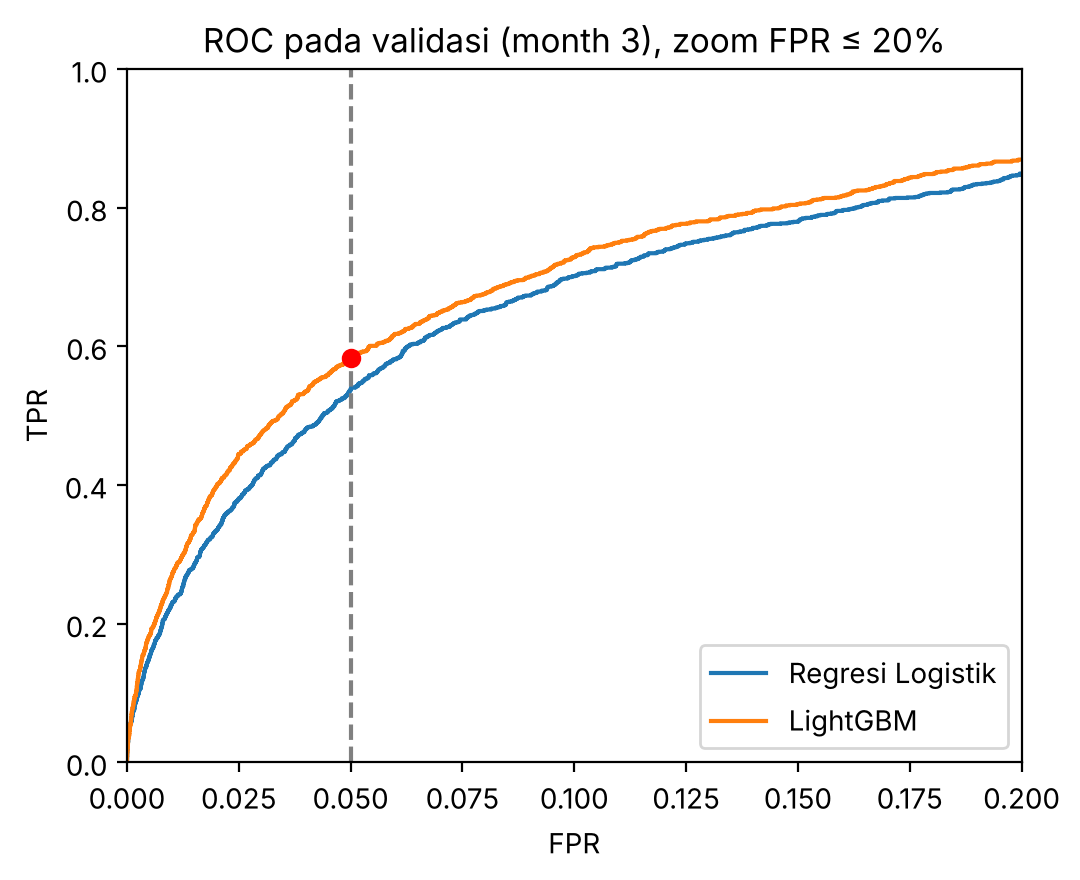

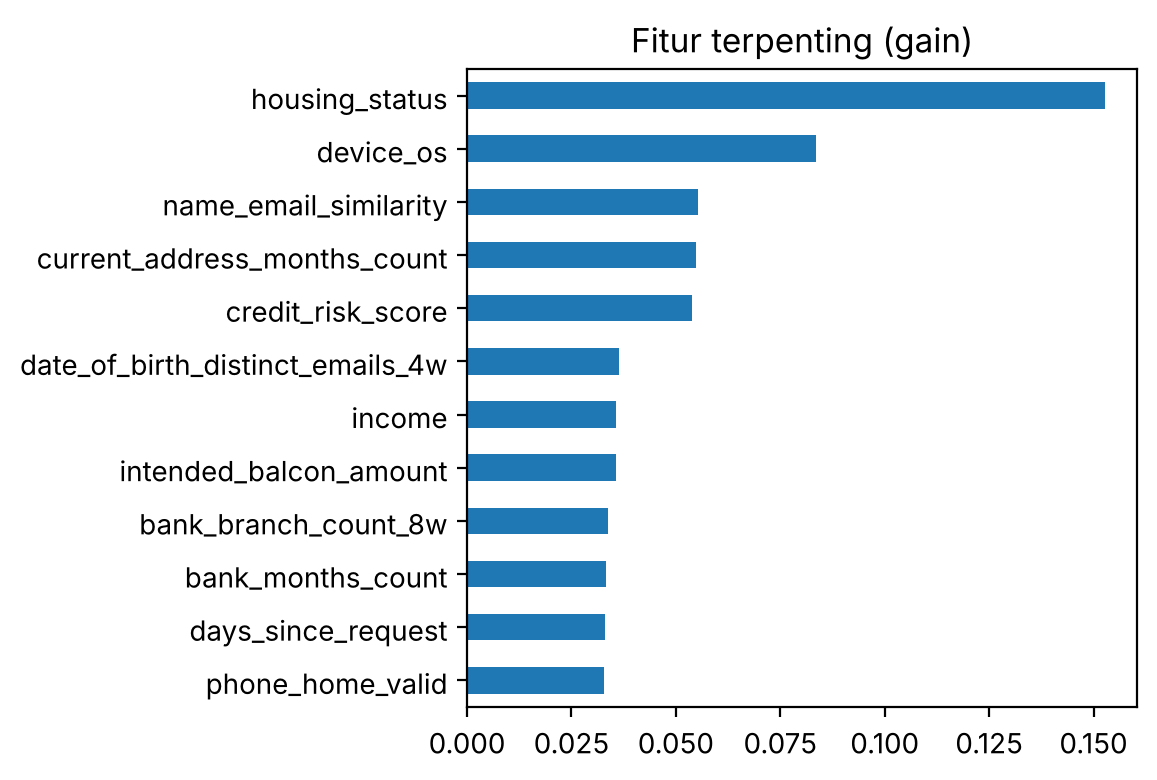

In [7]:
fpr_c, tpr_c, _ = roc_curve(y_val, s_val)
fpr_l, tpr_l, _ = roc_curve(y_val, s_lr_val)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr_l, tpr_l, label="Regresi Logistik"); plt.plot(fpr_c, tpr_c, label="LightGBM")
plt.axvline(0.05, ls="--", c="gray"); plt.scatter([0.05], [tpr_val], c="red", zorder=5)
plt.xlim(0, 0.2); plt.ylim(0, 1); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("ROC pada validasi (month 3), zoom FPR ≤ 20%"); plt.legend(); plt.tight_layout(); plt.show()

imp = pd.Series(model.booster_.feature_importance("gain"), index=X_fin.columns).sort_values(ascending=False)
(imp / imp.sum()).head(12).iloc[::-1].plot.barh(figsize=(6, 4), title="Fitur terpenting (gain)"); plt.tight_layout(); plt.show()

## 7. Simpan model dan uji muat ulang

In [8]:
bundle = {"model": model, "categories": cats, "threshold": float(thr_val_own),
          "threshold_note": "ambang pada FPR 5% di validasi month 3 untuk model final",
          "val_tpr_at_fpr5": float(tpr_val), "val_auc": float(roc_auc_score(y_val, s_val))}
joblib.dump(bundle, "fraud_model.joblib", compress=3)

# uji: muat ulang dan hasilnya harus identik
b = joblib.load("fraud_model.joblib")
Xc, _ = prepare(val, b["categories"])
s_re = b["model"].predict_proba(Xc)[:, 1]
assert np.allclose(s_re, s_val), "Skor model yang dimuat ulang berbeda!"
print("OK: model tersimpan & bisa dimuat ulang. Ukuran file: %.1f MB" % (os.path.getsize("fraud_model.joblib") / 1e6))
print(f"TPR@FPR5% (validasi month 3): {tpr_val:.4f}")

OK: model tersimpan & bisa dimuat ulang. Ukuran file: 0.8 MB
TPR@FPR5% (validasi month 3): 0.5826


### Cara memakai model untuk pengajuan baru
```python
import joblib; from fraud_utils import prepare
b = joblib.load("fraud_model.joblib")
X, _ = prepare(df_baru, b["categories"])      # df_baru: kolom sama seperti Base.csv
skor = b["model"].predict_proba(X)[:, 1]      # makin tinggi makin mungkin penipuan
tandai = skor > b["threshold"]
```